<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Outliers**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis or EDA. 
You will explore the distribution of key variables and focus on identifying outliers in this lab.


## Objectives


In this lab, you will perform the following:


-  Analyze the distribution of key variables in the dataset.

-  Identify and remove outliers using statistical methods.

-  Perform relevant statistical and correlation analysis.


#### Install and import the required libraries


In [2]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 127.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 178.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 142.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 120.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 147.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


<h3>Step 1: Load and Explore the Dataset</h3>


Load the dataset into a DataFrame and examine the structure of the data.


In [3]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

#Create the dataframe
df = pd.read_csv(file_url)

#Display the top 10 records
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 2: Plot the Distribution of Industry</h3>


Explore how respondents are distributed across different industries.

- Plot a bar chart to visualize the distribution of respondents by industry.

- Highlight any notable trends.


Industry
NaN                                           36579
Software Development                          11918
Other:                                         3077
Fintech                                        1641
Internet, Telecomm or Information Services     1629
Banking/Financial Services                     1371
Healthcare                                     1277
Manufacturing                                  1265
Retail and Consumer Services                   1264
Government                                      962
Media & Advertising Services                    894
Higher Education                                890
Transportation, or Supply Chain                 859
Computer Systems Design and Services            844
Energy                                          578
Insurance                                       389
Name: count, dtype: int64


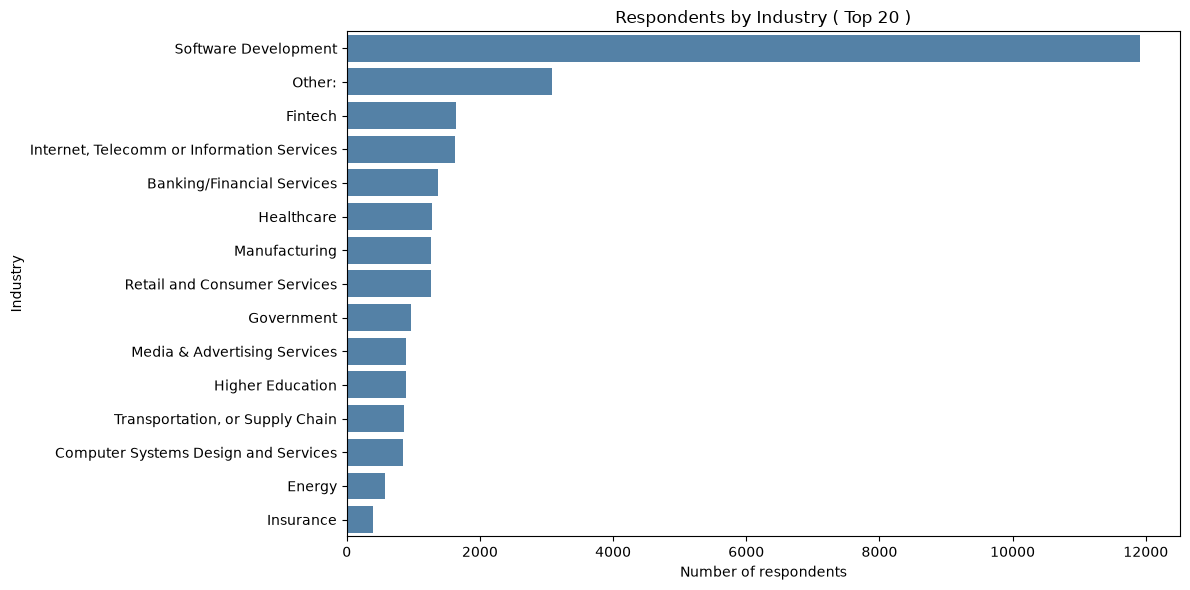

In [4]:
##Write your code here
# Plot respondent distribution by Industry, if available
if "Industry" in df.columns:
    industry_counts=df['Industry'].value_counts(dropna=False).head(20)
    print(industry_counts)
    plt.figure(figsize=(12,6))
    sns.barplot(x=industry_counts.values, y=industry_counts.index,color='steelblue')
    plt.title('Respondents by Industry ( Top 20 )')
    plt.xlabel('Number of respondents')
    plt.ylabel('Industry')
    plt.tight_layout()
    plt.show()
else:
    print('Industry is not availabe in this dataset version.')
    print('Available categorical alternatives:', df.select_dtypes(include='object').columns.tolist())

<h3>Step 3: Identify High Compensation Outliers</h3>


Identify respondents with extremely high yearly compensation.

- Calculate basic statistics (mean, median, and standard deviation) for `ConvertedCompYearly`.

- Identify compensation values exceeding a defined threshold (e.g., 3 standard deviations above the mean).


In [5]:
##Write your code here
#Basic statistics and high-compensation threshold
compensation=pd.to_numeric(df['ConvertedCompYearly'],errors='coerce').dropna()
comp_mean=compensation.mean()
comp_median=compensation.median()
comp_std=compensation.std()
high_threshold= comp_mean+3*comp_std
high_compensation=compensation[compensation>high_threshold]

print('Mean:', comp_mean)
print('Median:', comp_median)
print('Standard deviation:', comp_std)
print('3-standard-deviation threshold:', high_threshold)
print('High-compensation outliers:', len(high_compensation))


Mean: 86155.28726264134
Median: 65000.0
Standard deviation: 186756.97308629754
3-standard-deviation threshold: 646426.206521534
High-compensation outliers: 89


<h3>Step 4: Detect Outliers in Compensation</h3>


Identify outliers in the `ConvertedCompYearly` column using the IQR method.

- Calculate the Interquartile Range (IQR).

- Determine the upper and lower bounds for outliers.

- Count and visualize outliers using a box plot.


Q1: 32712.0 Q3: 107971.5 IQR: 75259.5
Lower bound: -80177.25 Upper bound: 220860.75
Number of IQR outliers: 978


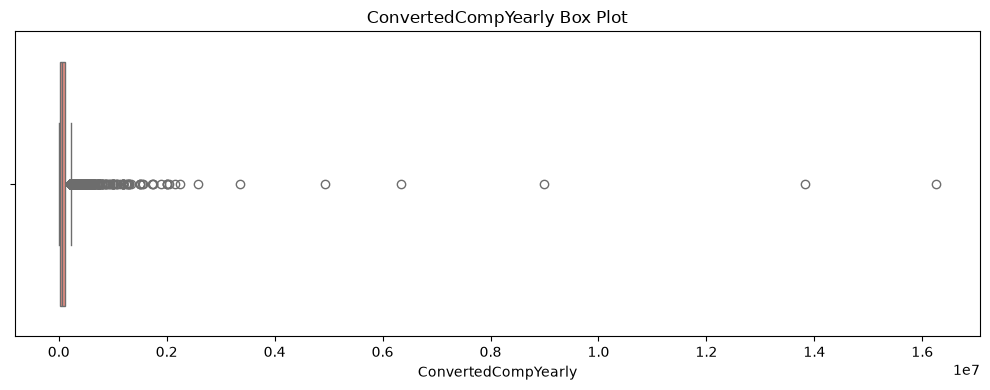

In [6]:
##Write your code here
# Identify compensation outliers using the IQR method
q1 = compensation.quantile(0.25)
q3 = compensation.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# outliers = data[(data < lower_bound) | (data > upper_bound)] 
outlier_mask = (
    pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
      .lt(lower_bound)
      | pd.to_numeric(df['ConvertedCompYearly'], errors='coerce').gt(upper_bound)
) # Create a boolean mask for outliers based on the IQR method
outlier_mask = outlier_mask.fillna(False) # fill NaN values with False to avoid counting them as outliers
print('Q1:', q1, 'Q3:', q3, 'IQR:', iqr)
print('Lower bound:', lower_bound, 'Upper bound:', upper_bound)
print('Number of IQR outliers:', outlier_mask.sum())

plt.figure(figsize=(10, 4))
sns.boxplot(x=compensation, color='salmon')
plt.title('ConvertedCompYearly Box Plot')
plt.xlabel('ConvertedCompYearly')
plt.tight_layout()
plt.show()

<h3>Step 5: Remove Outliers and Create a New DataFrame</h3>


Remove outliers from the dataset.

- Create a new DataFrame excluding rows with outliers in `ConvertedCompYearly`.
- Validate the size of the new DataFrame.


In [7]:
##Write your code here
# Remove IQR outliers and create a new DataFrame
df_no_outliers = df.loc[~outlier_mask].copy() # Create a new DataFrame without the outliers. '~' operator negates the boolean mask, selecting only the rows that are not outliers.
print('Rows before removing outliers:', len(df))
print('Rows after removing outliers:', len(df_no_outliers)) 
print('Rows removed:', len(df)-len(df_no_outliers))
print('Remaining outliers:',int(outlier_mask.loc[df_no_outliers.index].sum())) # Count the number of remaining outliers in the new DataFrame by applying the outlier mask to the index of df_no_outliers and summing the True values.

Rows before removing outliers: 65437
Rows after removing outliers: 64459
Rows removed: 978
Remaining outliers: 0


<h3>Step 6: Correlation Analysis</h3>


Analyze the correlation between `Age` (transformed) and other numerical columns.

- Map the `Age` column to approximate numeric values.

- Compute correlations between `Age` and other numeric variables.

- Visualize the correlation matrix.


Age_numeric            1.000000
WorkExp                0.851248
ConvertedCompYearly    0.367714
JobSat                 0.068299
CompTotal             -0.002799
JobSatPoints_1        -0.029405
ResponseId            -0.031545
JobSatPoints_8        -0.045845
JobSatPoints_6        -0.049758
JobSatPoints_4        -0.075065
JobSatPoints_9        -0.080287
JobSatPoints_7        -0.080309
JobSatPoints_5        -0.100472
JobSatPoints_11       -0.106081
JobSatPoints_10       -0.112117
Name: Age_numeric, dtype: float64


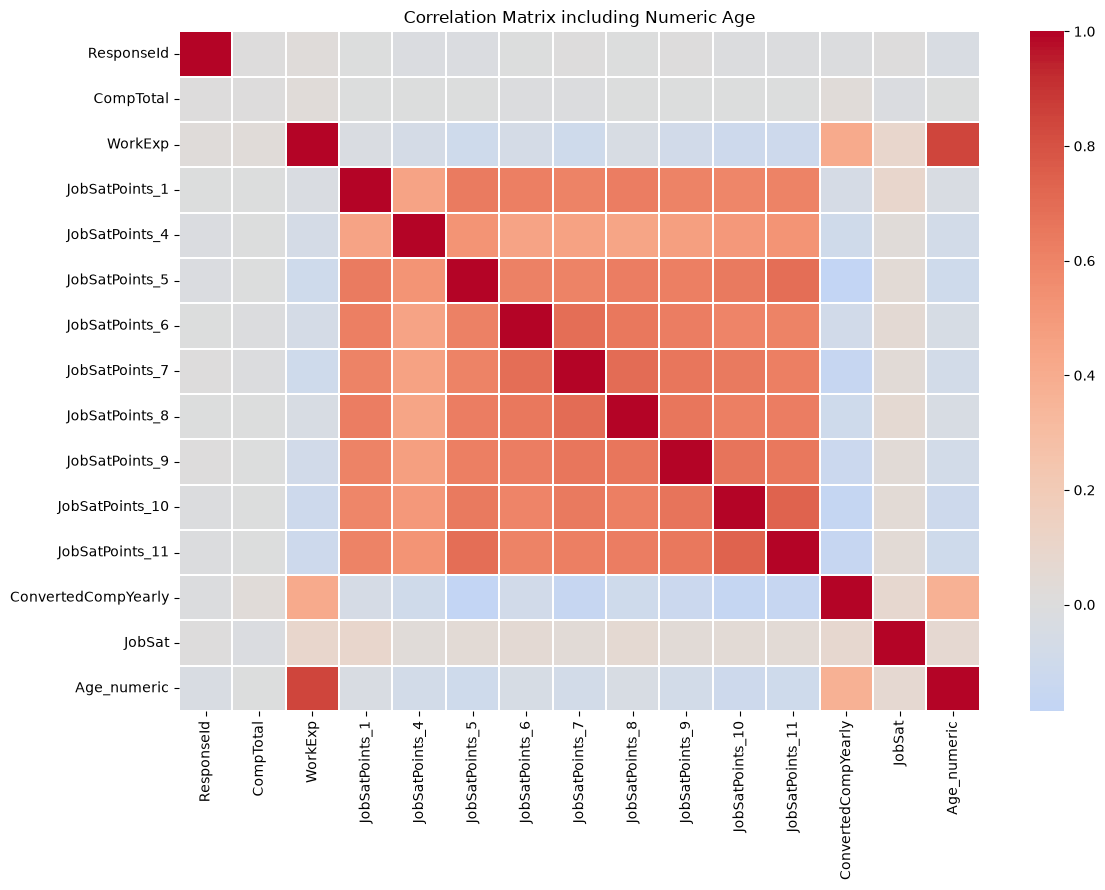

In [8]:
##Write your code here
# Map age ranges to approximate numeric values
age_mapping = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29,
    '35-44 years old': 39,
    '45-54 years old': 49,
    '55-64 years old': 59,
    '65 years or older': 70
}
df_corr=df_no_outliers.copy()
df_corr['Age_numeric']=df_corr['Age'].map(age_mapping)

# convert numeric-like columns and calculate the correlation matrix
numeric_candidates= df_corr.select_dtypes(include='number').columns.tolist()  # Select columns with numeric data types
numeric_data=df_corr[numeric_candidates].copy()# Create a new DataFrame with only numeric columns
correlation_matrix=numeric_data.corr() # Calculate the correlation matrix for the numeric data
print(correlation_matrix['Age_numeric'].sort_values(ascending=False))

plt.figure(figsize=(12,9))
sns.heatmap(correlation_matrix,cmap='coolwarm',center=0,linewidths=0.3)
plt.title('Correlation Matrix including Numeric Age')
plt.tight_layout()
plt.show()

<h3> Summary </h3>


In this lab, you developed essential skills in **Exploratory Data Analysis (EDA)** with a focus on outlier detection and removal. Specifically, you:


- Loaded and explored the dataset to understand its structure.

- Analyzed the distribution of respondents across industries.

- Identified and removed high compensation outliers using statistical thresholds and the Interquartile Range (IQR) method.

- Performed correlation analysis, including transforming the `Age` column into numeric values for better analysis.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-1|1.1|Madhusudan Moole|Reviewed and updated lab|                                                                                    
|2024-09-29|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
